# Animación mejorada del movimiento de kinesina

Este notebook construye una animación didáctica con una pista de microtúbulo estilizada, dos cabezas representadas esquemáticamente, un enlazador, rastro de posición, tiempo y anotación del evento. **No es una reconstrucción estructural ni una simulación mecánica de las dos cabezas.**

In [1]:
from pathlib import Path
import sys

# Find the project root whether JupyterLab was launched from the repository
# root or from the notebooks/ folder.
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in candidates if (path / "src" / "protein_motor_sim").is_dir()),
    None,
)
if PROJECT_ROOT is not None:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

print("Project root:", PROJECT_ROOT or "package expected to be installed in this kernel")

Project root: /home/zix/ProteinMotorSim


## 1. Simular una trayectoria

Reducimos el tiempo de observación para que la animación sea ligera. La trayectoria y sus eventos siguen procediendo del algoritmo de Gillespie.

In [2]:
from protein_motor_sim import Environment, GillespieSimulator, Kinesin1

motor = Kinesin1()
environment = Environment(
    atp_concentration=1.0e-3,
    external_force_N=0.5e-12,
    temperature_K=310.0,
)
trajectory = GillespieSimulator().run(
    motor=motor,
    environment=environment,
    t_max=0.20,
    seed=17,
)

print(f"Registros: {len(trajectory.times_s)}")
print(f"Desplazamiento neto: {trajectory.displacement_nm:.2f} nm")
print(f"Eventos: {trajectory.events}")

Registros: 25
Desplazamiento neto: 57.40 nm
Eventos: ['initial', 'atp_binding', 'atp_hydrolysis', 'forward_step', 'atp_binding', 'atp_hydrolysis', 'forward_step', 'atp_binding', 'atp_hydrolysis', 'forward_step', 'atp_binding', 'atp_hydrolysis', 'forward_step', 'atp_binding', 'atp_hydrolysis', 'forward_step', 'atp_binding', 'atp_hydrolysis', 'forward_step', 'atp_binding', 'atp_hydrolysis', 'forward_step', 'atp_binding', 'atp_hydrolysis', 'observation_end']


## 2. Animación de la caminata

Cada transición cinética se muestra como un evento. Los pasos se interpolan visualmente para que el salto no sea una transición gráfica abrupta; esta interpolación es solo visual y no modifica la trayectoria simulada.

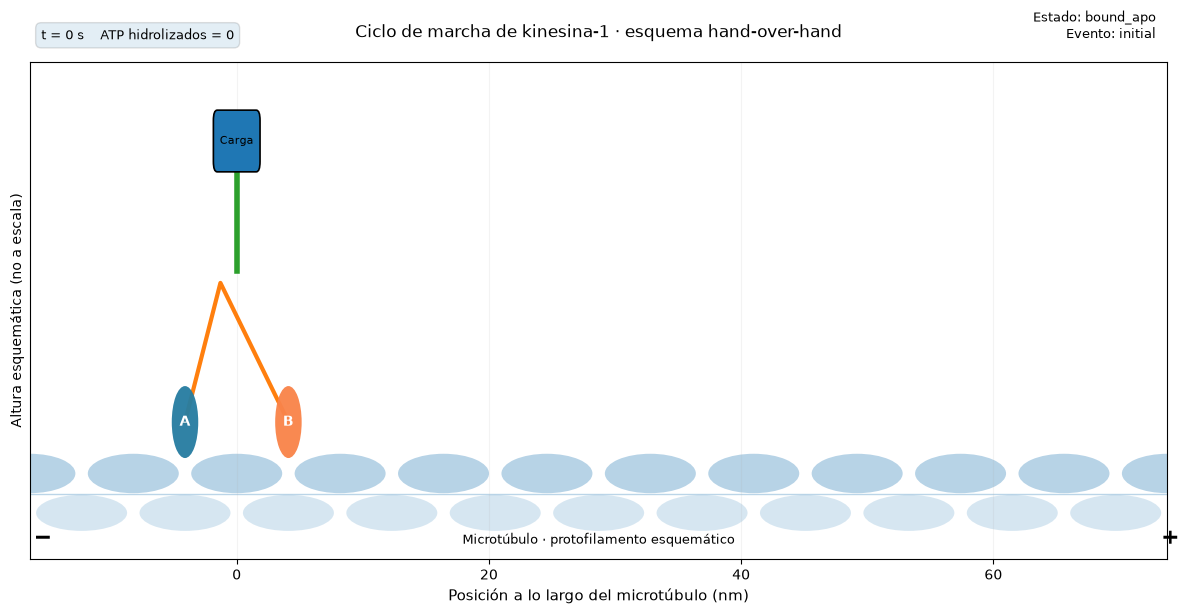

In [3]:
from IPython.display import HTML, display
from protein_motor_sim.visualization.animation import AnimationStyle, animate_kinesin_walk

animation = animate_kinesin_walk(
    trajectory,
    style=AnimationStyle(
        step_size_nm=motor.step_size_nm,
        frames_per_step=10,
        arc_height=3.0,
        interval_ms=60,
        trail_length=14,
    ),
)
display(HTML(animation.to_jshtml()))

## 3. Inspeccionar la secuencia de eventos

La animación es una representación visual. Para el análisis cuantitativo debemos consultar siempre los datos de la trayectoria.

In [4]:
events_table = [
    {
        "time_s": time_s,
        "position_nm": position_nm,
        "state": state,
        "event": event,
    }
    for time_s, position_nm, state, event in zip(
        trajectory.times_s, trajectory.positions_nm, trajectory.states, trajectory.events
    )
]
for record in events_table[:20]:
    print(record)

{'time_s': 0.0, 'position_nm': 0.0, 'state': 'bound_apo', 'event': 'initial'}
{'time_s': 0.0001682923139533298, 'position_nm': 0.0, 'state': 'atp_bound', 'event': 'atp_binding'}
{'time_s': 0.007446021134156096, 'position_nm': 0.0, 'state': 'post_hydrolysis', 'event': 'atp_hydrolysis'}
{'time_s': 0.024670620444232107, 'position_nm': 8.2, 'state': 'bound_apo', 'event': 'forward_step'}
{'time_s': 0.025518677628200356, 'position_nm': 8.2, 'state': 'atp_bound', 'event': 'atp_binding'}
{'time_s': 0.029332972939411433, 'position_nm': 8.2, 'state': 'post_hydrolysis', 'event': 'atp_hydrolysis'}
{'time_s': 0.04468510945137877, 'position_nm': 16.4, 'state': 'bound_apo', 'event': 'forward_step'}
{'time_s': 0.04716463008537952, 'position_nm': 16.4, 'state': 'atp_bound', 'event': 'atp_binding'}
{'time_s': 0.049452039296574005, 'position_nm': 16.4, 'state': 'post_hydrolysis', 'event': 'atp_hydrolysis'}
{'time_s': 0.05579837629446789, 'position_nm': 24.599999999999998, 'state': 'bound_apo', 'event': '